<a href="https://colab.research.google.com/github/Thathsara-Devindi/SSTRE-LTNLL/blob/main/LTNLL_Research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LTNLL Research — Phase 1 + Phase 2

- **Phase 1:** CIFAR-10N `random_label1`, true-class exponential long tail (imbalance factor 10), train/clean validation split, stable sample IDs.
- **Phase 2:** One standard ResNet-18 baseline trained on **observed human-noisy labels** only; evaluate on clean validation, save best/last checkpoints and per-epoch probabilities on the *training* images using deterministic analysis transforms.
- **Future:** Derive confidence (C) and temporal (T) signals from this **same baseline run**. Phase 2 does not implement signal-weighted learning yet.

**Experiment constraints:** CIFAR-10N human-noise + 18,388 training images is a different protocol from the synthetic-noise pilot with 20,431 images. These raw results must not be directly compared as if they were identical conditions.



## 1) Imports + settings

`SEED` Setting a fixed seed value ensures that the dataset selection process is fully reproducible

`IMBALANCE_FACTOR=10`: The sample size ratio between the largest (most frequent) and smallest (least frequent) classes is set to 10:1.

`VAL_PER_CLASS=500`: 500 clean images per class are allocated from the original CIFAR-10 training set to construct the validation set.

In [1]:
import os, json, random
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms

SEED = 42
NUM_CLASSES = 10
IMBALANCE_FACTOR = 10
VAL_PER_CLASS = 500
BATCH_SIZE = 128
NOISE_VARIANT = "random_label1"   # official CIFAR-10N real human-noise labels

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Seed:", SEED)
print("Noise variant:", NOISE_VARIANT)

Device: cuda
Seed: 42
Noise variant: random_label1


## 2) load CIFAR-10 images

CIFAR-10 **original train images 50,000** & **official untouched test images 10,000**. seperate Training augmentation & analysis/evaluation transform

In [2]:
MEAN = (0.4914, 0.4822, 0.4465)
STD  = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

train_raw = datasets.CIFAR10(root='./data', train=True, download=True)
test_dataset = datasets.CIFAR10(root='./data', train=False, download=True,
                               transform=eval_transform)
clean_targets_full = np.asarray(train_raw.targets, dtype=np.int64)

assert len(train_raw) == 50000 and len(test_dataset) == 10000
assert all(np.sum(clean_targets_full == c) == 5000 for c in range(NUM_CLASSES))
print('Original train images:', len(train_raw))
print('Official clean test images:', len(test_dataset))
print('Class names:', train_raw.classes)

100%|██████████| 170M/170M [41:32<00:00, 68.4kB/s]


Original train images: 50000
Official clean test images: 10000
Class names: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 3) load Official **human noisy labels**

Noise Type Update: The previous notebook utilized artificially generated 20% symmetric noise, whereas the current implementation uses the official CIFAR-10N human annotations.

random_label1: This refers to a specific human-annotated noise variant. The actual noise percentage for this variant is calculated dynamically in the output

Data Source: The CIFAR-10_human.pt source file is retrieved directly from the official GitHub repository.



In [3]:
noise_path = Path('./data/CIFAR-10_human.pt')
noise_url = 'https://raw.githubusercontent.com/UCSC-REAL/cifar-10-100n/main/data/CIFAR-10_human.pt'
if not noise_path.exists():
    print('Downloading official CIFAR-10N annotations...')
    urlretrieve(noise_url, noise_path)

assert noise_path.stat().st_size > 100_000, 'Annotation file download looks incomplete.'
# This file is fetched only from the named official CIFAR-10N project
noise_data = torch.load(str(noise_path), map_location='cpu', weights_only=False)
print('Available annotation keys:', list(noise_data.keys()))

human_clean = np.asarray(noise_data['clean_label'], dtype=np.int64)
human_observed_full = np.asarray(noise_data[NOISE_VARIANT], dtype=np.int64)

assert human_clean.shape == (50000,)
assert human_observed_full.shape == (50000,)
assert np.array_equal(human_clean, clean_targets_full), (
    'CIFAR-10 and CIFAR-10N label order do not match. STOP; do not continue.'
)
assert np.all((human_observed_full >= 0) & (human_observed_full < NUM_CLASSES))
print('CIFAR-10N annotation order verified ✅')
print('Full 50k human noise rate:', round(100 * np.mean(human_observed_full != human_clean), 2), '%')

Available annotation keys: ['clean_label', 'aggre_label', 'worse_label', 'random_label1', 'random_label2', 'random_label3']
CIFAR-10N annotation order verified ✅
Full 50k human noise rate: 17.23 %


## 4) Clean validation set **first** separate

Validation Set Allocation: 500 examples per class are extracted from the original training data to construct the validation set

Strict Data Isolation: These validation examples are strictly excluded from the model training process

Dataset Roles: The clean-labeled validation set is utilized exclusively for model selection, while the untouched test set is reserved for final performance reporting


In [4]:
rng_split = np.random.default_rng(SEED)
val_indices_parts = []
train_pool_parts = []

for cls in range(NUM_CLASSES):
    positions = np.where(clean_targets_full == cls)[0]
    rng_split.shuffle(positions)
    val_indices_parts.append(positions[:VAL_PER_CLASS])
    train_pool_parts.append(positions[VAL_PER_CLASS:])

val_indices = np.concatenate(val_indices_parts).astype(np.int64)
train_pool_indices = np.concatenate(train_pool_parts).astype(np.int64)
rng_split.shuffle(val_indices)
rng_split.shuffle(train_pool_indices)

assert len(val_indices) == 5000
assert len(train_pool_indices) == 45000
assert len(np.intersect1d(val_indices, train_pool_indices)) == 0
print('Clean validation:', len(val_indices))
print('Training candidate pool:', len(train_pool_indices))
print('Train/validation overlap: 0 ✅')

Clean validation: 5000
Training candidate pool: 45000
Train/validation overlap: 0 ✅


## 5) create Long-tailed **training** subset

Clean source labels **use for select subset only**. get for training label  *human noisy label* . In Literature used this idea - `long-tail first, noisy noisy labels next`

Preserve Validation class balance , max train-class size eka `4500`

In [5]:
rng_tail = np.random.default_rng(SEED + 1)
MAX_TRAIN_PER_CLASS = 5000 - VAL_PER_CLASS
class_counts_target = [int(MAX_TRAIN_PER_CLASS * (1 / IMBALANCE_FACTOR) **
                          (cls / (NUM_CLASSES - 1))) for cls in range(NUM_CLASSES)]
selected_parts = []
for cls in range(NUM_CLASSES):
    pool_cls = train_pool_indices[clean_targets_full[train_pool_indices] == cls]
    chosen = rng_tail.choice(pool_cls, size=class_counts_target[cls], replace=False)
    selected_parts.append(chosen)

lt_indices = np.concatenate(selected_parts).astype(np.int64)
rng_tail.shuffle(lt_indices)

clean_selected = clean_targets_full[lt_indices]          # Audit only
observed_selected = human_observed_full[lt_indices]      # TRAINING LABELS
is_noisy = observed_selected != clean_selected           # Audit only

assert len(lt_indices) == len(np.unique(lt_indices))
assert len(np.intersect1d(lt_indices, val_indices)) == 0
assert np.array_equal(np.bincount(clean_selected, minlength=NUM_CLASSES),
                      np.asarray(class_counts_target))
print('Long-tail training images:', len(lt_indices))
print('Target sizes by class:', class_counts_target)
print('Human noise rate in selected training set:', round(100*is_noisy.mean(),2), '%')

Long-tail training images: 18388
Target sizes by class: [4500, 3484, 2697, 2088, 1617, 1252, 969, 750, 581, 450]
Human noise rate in selected training set: 17.12 %


## 6) Sample metadata + groups

for Every image have  `local_index` — later `confidence`, `temporal`, `neighborhood` signals attach to correct sample essential.

`true_clean_label` & `is_noisy` data frame  audit only. **Training loop not using as input **

`Head/Medium/Tail`

In [6]:
head_classes = set(range(0, 3))
medium_classes = set(range(3, 7))
tail_classes = set(range(7, 10))

def get_group(cls):
    if cls in head_classes: return 'Head'
    if cls in medium_classes: return 'Medium'
    return 'Tail'

sample_info = pd.DataFrame({
    'local_index': np.arange(len(lt_indices)),
    'original_cifar_index': lt_indices,
    'observed_label': observed_selected,
    'true_clean_label_AUDIT_ONLY': clean_selected,
    'is_noisy_AUDIT_ONLY': is_noisy,
    'group_AUDIT_ONLY': [get_group(int(c)) for c in clean_selected]
})

print(sample_info.groupby('group_AUDIT_ONLY').agg(
    samples=('local_index','size'),
    noise_rate=('is_noisy_AUDIT_ONLY','mean')
).to_string())
print('\nFirst 5 rows:')
print(sample_info.head().to_string(index=False))

                  samples  noise_rate
group_AUDIT_ONLY                     
Head                10681    0.151578
Medium               5926    0.221735
Tail                 1781    0.120719

First 5 rows:
 local_index  original_cifar_index  observed_label  true_clean_label_AUDIT_ONLY  is_noisy_AUDIT_ONLY group_AUDIT_ONLY
           0                   775               2                            2                False             Head
           1                 15623               9                            0                 True             Head
           2                 10601               0                            0                False             Head
           3                 20434               0                            0                False             Head
           4                 17837               7                            7                False             Tail


## 7) Datasets + loaders

**Training:** image + observed noisy label + stable local sample ID.

**Analysis:** same training image IDs, but *without random augmentation* — future confidence/temporal measurements align correctly.

**Validation and test:** clean labels, only for evaluation. **Never backprop on validation/test.**

In [7]:
class IndexedNoisyCifarDataset(Dataset):
    def __init__(self, original_dataset, original_indices, observed_labels, transform):
        self.original_dataset = original_dataset
        self.original_indices = np.asarray(original_indices, dtype=np.int64)
        self.observed_labels = np.asarray(observed_labels, dtype=np.int64)
        self.transform = transform
        assert len(self.original_indices) == len(self.observed_labels)

    def __len__(self):
        return len(self.original_indices)

    def __getitem__(self, local_idx):
        original_idx = int(self.original_indices[local_idx])
        image, _unused_clean_label = self.original_dataset[original_idx]
        image = self.transform(image)
        # IMPORTANT: no clean label returned to the training method
        return image, int(self.observed_labels[local_idx]), int(local_idx)

class IndexedCleanCifarDataset(Dataset):
    def __init__(self, original_dataset, original_indices, transform):
        self.original_dataset = original_dataset
        self.original_indices = np.asarray(original_indices, dtype=np.int64)
        self.transform = transform

    def __len__(self):
        return len(self.original_indices)

    def __getitem__(self, i):
        img, correct_label = self.original_dataset[int(self.original_indices[i])]
        return self.transform(img), int(correct_label)

train_dataset = IndexedNoisyCifarDataset(train_raw, lt_indices, observed_selected, train_transform)
analysis_dataset = IndexedNoisyCifarDataset(train_raw, lt_indices, observed_selected, eval_transform)
val_dataset = IndexedCleanCifarDataset(train_raw, val_indices, eval_transform)

loader_kwargs = {'num_workers': 2, 'pin_memory': (device.type == 'cuda')}
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs)
analysis_loader = DataLoader(analysis_dataset, batch_size=256, shuffle=False, **loader_kwargs)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False, **loader_kwargs)

batch = next(iter(train_loader))
print('Train batch image shape:', tuple(batch[0].shape))
print('Observed label shape:', tuple(batch[1].shape))
print('Local IDs shape:', tuple(batch[2].shape))
print('Training dataset length:', len(train_dataset))
print('Analysis dataset length:', len(analysis_dataset))
print('Validation dataset length:', len(val_dataset))
print('Test dataset length:', len(test_dataset))

Train batch image shape: (128, 3, 32, 32)
Observed label shape: (128,)
Local IDs shape: (128,)
Training dataset length: 18388
Analysis dataset length: 18388
Validation dataset length: 5000
Test dataset length: 10000


## 8) Final verification — **RUN THIS BEFORE ANY TRAINING**

Expected:
- Dataset source CIFAR-10N human annotations
- Long-tail class counts decreasing
- Train/validation overlap = zero
- Noise rate actually computed
- Training sample IDs and observed labels aligned
- Training batch shapes correct

**Note:**
Benchmark Comparability: Due to the extraction of a separate validation set in this protocol, the resulting benchmark scores cannot be directly compared with those reported in published papers (which often train on the full dataset).

Documentation: This methodological discrepancy will be explicitly addressed and documented during the subsequent baseline comparison phase.

✅ PHASE 1 CHECKS PASSED
Training samples: 18388
Val samples: 5000
Test samples: 10000
Observed human noise rate: 17.12%


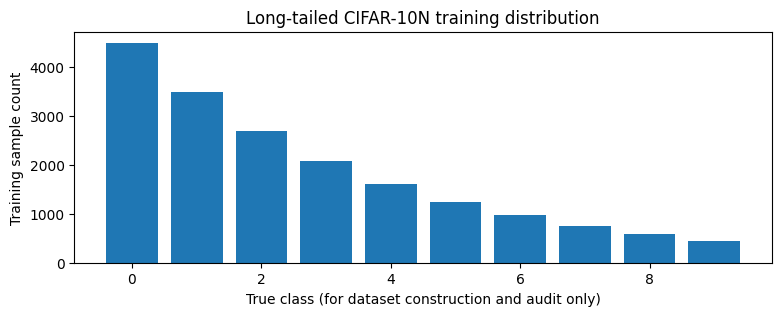

✅ Experiment metadata saved under ./artifacts/ (Colab runtime storage).
IMPORTANT: Save/download these artifacts or copy them to Google Drive before resetting runtime.


In [8]:
assert set(lt_indices).isdisjoint(set(val_indices))
assert len(train_dataset) == len(analysis_dataset) == len(sample_info)
assert len(val_dataset) == 5000 and len(test_dataset) == 10000
assert np.array_equal(sample_info['local_index'].values, np.arange(len(sample_info)))
for sample_id in [0, len(sample_info)//2, len(sample_info)-1]:
    _, observed, returned_id = analysis_dataset[sample_id]
    assert returned_id == sample_id
    assert observed == sample_info.loc[sample_id, 'observed_label']

print('✅ PHASE 1 CHECKS PASSED')
print('Training samples:', len(train_dataset))
print('Val samples:', len(val_dataset))
print('Test samples:', len(test_dataset))
print('Observed human noise rate:', f'{100*is_noisy.mean():.2f}%')

plt.figure(figsize=(9,3))
plt.bar(range(NUM_CLASSES), np.bincount(clean_selected, minlength=NUM_CLASSES))
plt.xlabel('True class (for dataset construction and audit only)')
plt.ylabel('Training sample count')
plt.title('Long-tailed CIFAR-10N training distribution')
plt.show()

os.makedirs('artifacts', exist_ok=True)
sample_info.to_csv('artifacts/dataset_metadata_AUDIT_ONLY.csv', index=False)
np.savez_compressed('artifacts/dataset_split_v2.npz',
                    lt_indices=lt_indices, val_indices=val_indices,
                    observed_labels=observed_selected,
                    clean_labels_AUDIT_ONLY=clean_selected,
                    is_noisy_AUDIT_ONLY=is_noisy)
with open('artifacts/phase1_config.json', 'w') as f:
    json.dump({'seed': SEED, 'dataset': 'CIFAR-10N', 'noise_variant': NOISE_VARIANT,
               'imbalance_factor': IMBALANCE_FACTOR, 'val_per_class': VAL_PER_CLASS,
               'train_size': len(train_dataset), 'actual_noise_rate': float(is_noisy.mean())},
               f, indent=2)
print('✅ Experiment metadata saved under ./artifacts/ (Colab runtime storage).')
print('IMPORTANT: Save/download these artifacts or copy them to Google Drive before resetting runtime.')

# PHASE 1 COMPLETE ✅

If Phase 1 checks above pass, continue with **Phase 2 below in the SAME notebook**. No separate Phase 2 notebook is needed. When Colab restarts, re-run Phase 1 cells to reconstruct the same dataset objects; the saved indices and checkpoint guards below verify consistency.


# Phase 2 — Single ResNet-18 baseline (same notebook)


**No confident or temporal weighting is being applied in Phase 2.** This is the *ordinary* baseline against which the proposed method must later be compared using identical protocols.


## 9) Google Drive connect + Phase 1 split permanent save (do this before training)


In [10]:
import shutil
import hashlib
from pathlib import Path

# 1) Require GPU for Phase 2 (Phase 1 is allowed to run on CPU).
if not torch.cuda.is_available() or device.type != 'cuda':
    raise RuntimeError(
        'Phase 2 needs a GPU. In Colab: Runtime > Change runtime type > T4 GPU, '
        'then run all Phase 1 cells again before this Phase 2 cell.'
    )
print('GPU:', torch.cuda.get_device_name(0))

# 2) Independent of Google Drive: stable identifier for the exact dataset/split/labels.
SPLIT_FINGERPRINT = hashlib.sha256(
    lt_indices.astype('<i8').tobytes()
    + val_indices.astype('<i8').tobytes()
    + observed_selected.astype('<i8').tobytes()
).hexdigest()
print('Split fingerprint:', SPLIT_FINGERPRINT[:16])

# 3) Storage. Try permanent Google Drive first, fall back safely to Colab storage.
USE_GOOGLE_DRIVE = True    # Set False only if Drive authentication cannot be fixed.
STORAGE_PERMANENT = False
if USE_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        mydrive = Path('/content/drive/MyDrive')
        if not mydrive.is_dir():
            raise RuntimeError('Google Drive mount did not expose /content/drive/MyDrive')
        PROJECT_ROOT = mydrive / 'LTNLL_Research'
        STORAGE_PERMANENT = True
    except Exception as exc:
        print('WARNING: Google Drive mount failed:', type(exc).__name__, str(exc))
        PROJECT_ROOT = Path('/content/artifacts/LTNLL_Research')
else:
    PROJECT_ROOT = Path('/content/artifacts/LTNLL_Research')

PHASE1_DRIVE = PROJECT_ROOT / 'Phase1_V2'   # variable name retained for later cells
PHASE2_DRIVE = PROJECT_ROOT / 'Phase2_V2'   # variable name retained for later cells
PHASE1_DRIVE.mkdir(parents=True, exist_ok=True)
PHASE2_DRIVE.mkdir(parents=True, exist_ok=True)

# 4) Preserve exact Phase 1 split, labels and metadata. Check if earlier saved copy differs.
source_dir = Path('artifacts')
required_files = ['dataset_split_v2.npz', 'dataset_metadata_AUDIT_ONLY.csv', 'phase1_config.json']
for filename in required_files:
    source_file = source_dir / filename
    target_file = PHASE1_DRIVE / filename
    if not source_file.is_file():
        raise FileNotFoundError(f'Missing {source_file}. Run Phase 1 through the final check cell first.')
    if target_file.exists():
        if filename.endswith('.npz'):
            with np.load(source_file) as new, np.load(target_file) as old:
                assert set(new.files) == set(old.files) and all(
                    np.array_equal(new[k], old[k]) for k in new.files
                ), f'Dataset split mismatch for {filename}! STOP.'
        elif filename.endswith('.json'):
            assert json.loads(source_file.read_text()) == json.loads(target_file.read_text()), (
                f'Config mismatch for {filename}! STOP.'
            )
        else:
            assert pd.read_csv(source_file).equals(pd.read_csv(target_file)), (
                f'Metadata mismatch for {filename}! STOP.'
            )
        print('Verified existing Phase 1 backup:', filename)
    else:
        shutil.copy2(source_file, target_file)
        print('Saved Phase 1 backup:', filename)

print('Phase 2 output folder:', PHASE2_DRIVE)
print('Permanent Google Drive storage:', STORAGE_PERMANENT)
if not STORAGE_PERMANENT:
    print('IMPORTANT: Local files will be LOST when Colab resets. Download backup after training!')
print('✅ PHASE 2 PREREQUISITES PASSED')


GPU: Tesla T4
Split fingerprint: 9a8f859c87102763
Mounted at /content/drive
Saved Phase 1 backup: dataset_split_v2.npz
Saved Phase 1 backup: dataset_metadata_AUDIT_ONLY.csv
Saved Phase 1 backup: phase1_config.json
Phase 2 output folder: /content/drive/MyDrive/LTNLL_Research/Phase2_V2
Permanent Google Drive storage: True
✅ PHASE 2 PREREQUISITES PASSED


## 10) Fixed baseline hyperparameters + model

- Train: observed `random_label1` human noisy labels (18,388 images), `train_loader` (random crop/flip).
- Validation: **clean 5,000** examples from the separate validation pool, never backpropagated.
- Architecture: ResNet-18 adapted to CIFAR's 32×32 images (`3×3` stem and no max-pool), no ImageNet pretrained weights.
- Baseline: standard cross-entropy, SGD momentum, MultiStepLR. **20 epochs initial controlled protocol**. If the study later requires longer training, change the protocol for **every** method, not just the proposed method.
- Selection: checkpoint with best **validation macro F1**, not test accuracy.
- `analysis_loader` returns `(image, observed_label, local_index)` in a fixed order. Histories from this model are useful for later C/T analyses, but their cleanliness performance is not evaluated yet.


In [11]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score

P2_EPOCHS = 20
P2_LR = 0.1
P2_MOMENTUM = 0.9
P2_WEIGHT_DECAY = 5e-4
P2_MILESTONES = [12, 17]
P2_GAMMA = 0.1

# Keep all future comparison methods on the SAME agreed settings.
P2_CONFIG = {
    'dataset': 'CIFAR-10N',
    'noise_variant': NOISE_VARIANT,
    'imbalance_factor': IMBALANCE_FACTOR,
    'seed': SEED,
    'split_fingerprint': SPLIT_FINGERPRINT,
    'train_size': len(train_dataset),
    'validation_size': len(val_dataset),
    'epochs': P2_EPOCHS,
    'batch_size': BATCH_SIZE,
    'optimizer': 'SGD',
    'lr': P2_LR,
    'momentum': P2_MOMENTUM,
    'weight_decay': P2_WEIGHT_DECAY,
    'lr_milestones': P2_MILESTONES,
    'lr_gamma': P2_GAMMA,
    'selection_metric': 'validation_macro_f1',
    'backbone': 'ResNet18_CIFAR_no_pretraining',
}
config_path = PHASE2_DRIVE / 'phase2_config.json'
if config_path.exists():
    assert json.loads(config_path.read_text()) == P2_CONFIG, (
        'Saved Phase 2 settings do not match! Use a new experiment folder '
        'for changed settings; do not overwrite existing results.'
    )
else:
    config_path.write_text(json.dumps(P2_CONFIG, indent=2))

# Seed AFTER dataset construction; on restart the checkpoint restores the RNG state.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

def make_resnet18_cifar():
    network = models.resnet18(weights=None)
    network.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
    network.maxpool = nn.Identity()
    network.fc = nn.Linear(network.fc.in_features, NUM_CLASSES)
    return network

baseline_model = make_resnet18_cifar().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(
    baseline_model.parameters(), lr=P2_LR,
    momentum=P2_MOMENTUM, weight_decay=P2_WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=P2_MILESTONES, gamma=P2_GAMMA
)

print('Model: ResNet-18 (CIFAR stem, no pretrained weights)')
print('Epochs:', P2_EPOCHS, '| batch size:', BATCH_SIZE)
print('Trainable parameters:', sum(p.numel() for p in baseline_model.parameters() if p.requires_grad))
print('Checkpoint selection: validation macro F1; official test set not used.')


Model: ResNet-18 (CIFAR stem, no pretrained weights)
Epochs: 20 | batch size: 128
Trainable parameters: 11173962
Checkpoint selection: validation macro F1; official test set not used.


## 11) Define baseline train/validate/analysis functions

train_one_baseline_epoch: Applies standard cross-entropy loss using the observed noisy labels. The local_index variable is not utilized in the training loss computation.

evaluate_validation: Evaluates the model on the separate, clean validation set using overall accuracy, balanced accuracy, macro F1 score, and group-wise accuracy metrics. The test set is strictly not accessed during this phase.

collect_analysis_probabilities: Records per-epoch predicted class probabilities into the correct matrix rows using a stable local sample ID. This exact mapping is critical; without it, future temporal signal calculations would mistakenly compare predictions of completely different images across epochs.


In [12]:
def train_one_baseline_epoch(model, loader):
    model.train()
    total_loss = 0.0
    total_correct = 0
    total = 0
    for images, observed_labels, _local_ids in loader:
        images = images.to(device, non_blocking=True)
        observed_labels = observed_labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, observed_labels)
        loss.backward()
        optimizer.step()
        batch_n = observed_labels.size(0)
        total_loss += loss.item() * batch_n
        total_correct += (logits.argmax(1) == observed_labels).sum().item()
        total += batch_n
    return total_loss / total, total_correct / total

@torch.inference_mode()
def evaluate_validation(model, loader):
    model.eval()
    true_all, pred_all = [], []
    for images, clean_labels in loader:
        logits = model(images.to(device, non_blocking=True))
        true_all.append(clean_labels.numpy())
        pred_all.append(logits.argmax(1).cpu().numpy())
    y_true = np.concatenate(true_all)
    y_pred = np.concatenate(pred_all)
    group_acc = {}
    for group_name, class_ids in [
        ('head', [0, 1, 2]), ('medium', [3, 4, 5, 6]), ('tail', [7, 8, 9])
    ]:
        mask = np.isin(y_true, class_ids)
        group_acc[f'val_{group_name}_acc'] = float(np.mean(y_true[mask] == y_pred[mask]))
    return {
        'val_accuracy': float(accuracy_score(y_true, y_pred)),
        'val_balanced_accuracy': float(balanced_accuracy_score(y_true, y_pred)),
        'val_macro_f1': float(f1_score(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                                       average='macro', zero_division=0)),
        **group_acc,
    }

@torch.inference_mode()
def collect_analysis_probabilities(model, loader, n_samples):
    model.eval()
    all_probs = np.full((n_samples, NUM_CLASSES), np.nan, dtype=np.float32)
    seen = np.zeros(n_samples, dtype=bool)
    for images, _observed_labels, local_ids in loader:
        logits = model(images.to(device, non_blocking=True))
        probs = F.softmax(logits, dim=1).cpu().numpy()
        ids = local_ids.numpy().astype(np.int64)
        assert np.all((0 <= ids) & (ids < n_samples)), 'Invalid sample ID.'
        assert not np.any(seen[ids]), 'Repeated local sample ID!'
        all_probs[ids] = probs
        seen[ids] = True
    assert np.all(seen), 'Some training images were missing from analysis predictions.'
    assert np.isfinite(all_probs).all()
    assert np.allclose(all_probs.sum(1), 1.0, atol=2e-5)
    return all_probs


## 12) Resume-safe experiment state

Every epoch a `baseline_last.pt` checkpoint will store the model/optimizer/scheduler state **and** historical prediction probabilities. This allows recovery after Colab disconnects. `baseline_best.pt` stores the selected model. Files stay on **your own Google Drive**.

**Security:** Load checkpoints only from your own trusted Drive folder. `torch.load(weights_only=False)` can load pickled content; it must never be used for untrusted downloads.


In [13]:
last_ckpt_path = PHASE2_DRIVE / 'baseline_last.pt'
best_ckpt_path = PHASE2_DRIVE / 'baseline_best.pt'
log_csv_path = PHASE2_DRIVE / 'baseline_training_history.csv'
probs_npz_path = PHASE2_DRIVE / 'baseline_probability_history.npz'

# float16 halves the saved probability-history size; softmax was computed in float32.
probability_history = np.full(
    (P2_EPOCHS, len(train_dataset), NUM_CLASSES), np.nan, dtype=np.float16
)
training_log = []
best_val_f1 = -float('inf')
start_epoch = 0

if last_ckpt_path.exists():
    state = torch.load(last_ckpt_path, map_location=device, weights_only=False)
    assert state['config'] == P2_CONFIG, 'Checkpoint metadata differs; do not resume.'
    baseline_model.load_state_dict(state['model_state_dict'])
    optimizer.load_state_dict(state['optimizer_state_dict'])
    scheduler.load_state_dict(state['scheduler_state_dict'])
    probability_history = state['probability_history']
    training_log = state['training_log']
    best_val_f1 = float(state['best_val_f1'])
    start_epoch = int(state['epoch_completed'])
    if 'torch_rng_state' in state:
        torch.set_rng_state(state['torch_rng_state'].cpu())
    if 'cuda_rng_state_all' in state and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(state['cuda_rng_state_all'])
    if 'numpy_rng_state' in state:
        np.random.set_state(state['numpy_rng_state'])
    if 'python_rng_state' in state:
        random.setstate(state['python_rng_state'])
    assert probability_history.shape == (P2_EPOCHS, len(train_dataset), NUM_CLASSES)
    assert len(training_log) == start_epoch
    print(f'RESUMED from saved epoch {start_epoch} / {P2_EPOCHS}')
else:
    print('No existing matching checkpoint. Starting baseline from epoch 1.')


No existing matching checkpoint. Starting baseline from epoch 1.


## 13) Train baseline + collect prediction history (long-running cell)

Every epoch: train → clean validation metrics → record **same-model** probabilities on entire training set → save best and last checkpoints.

In [14]:
for epoch_index in range(start_epoch, P2_EPOCHS):
    epoch_number = epoch_index + 1
    train_loss, train_observed_acc = train_one_baseline_epoch(baseline_model, train_loader)
    val_metrics = evaluate_validation(baseline_model, val_loader)
    # IMPORTANT: probabilities are from this very same baseline model/epoch,
    # on training images with NO random augmentation.
    p_epoch = collect_analysis_probabilities(baseline_model, analysis_loader, len(train_dataset))
    probability_history[epoch_index] = p_epoch.astype(np.float16)

    log_row = {
        'epoch': epoch_number,
        'train_noisy_label_loss': float(train_loss),
        'train_observed_label_accuracy': float(train_observed_acc),
        'lr': float(optimizer.param_groups[0]['lr']),
        **val_metrics,
    }
    training_log.append(log_row)

    improved = val_metrics['val_macro_f1'] > best_val_f1
    if improved:
        best_val_f1 = val_metrics['val_macro_f1']
        torch.save({
            'model_state_dict': baseline_model.state_dict(),
            'epoch': epoch_number,
            'best_val_macro_f1': best_val_f1,
            'config': P2_CONFIG,
        }, best_ckpt_path)

    scheduler.step()
    torch.save({
        'epoch_completed': epoch_number,
        'model_state_dict': baseline_model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'probability_history': probability_history,
        'training_log': training_log,
        'best_val_f1': best_val_f1,
        'config': P2_CONFIG,
        'torch_rng_state': torch.get_rng_state(),
        'cuda_rng_state_all': torch.cuda.get_rng_state_all(),
        'numpy_rng_state': np.random.get_state(),
        'python_rng_state': random.getstate(),
    }, last_ckpt_path)
    pd.DataFrame(training_log).to_csv(log_csv_path, index=False)

    print(
        f"Epoch {epoch_number:02d}/{P2_EPOCHS} | "
        f"train loss {train_loss:.4f} | "
        f"train obs-acc {train_observed_acc:.2%} | "
        f"val acc {val_metrics['val_accuracy']:.2%} | "
        f"val macro-F1 {val_metrics['val_macro_f1']:.4f} | "
        f"val tail acc {val_metrics['val_tail_acc']:.2%}"
        + (' | saved BEST' if improved else '')
    )

# Compact portable history file for Phase 3 (confidence/temporal analysis).
completed_epochs = len(training_log)
assert completed_epochs == P2_EPOCHS, f'Only {completed_epochs}/{P2_EPOCHS} completed.'
np.savez_compressed(
    probs_npz_path,
    probability_history=probability_history,
    selected_train_original_indices=lt_indices,
    observed_training_labels=observed_selected,
    split_fingerprint=np.array(SPLIT_FINGERPRINT),
)
print('\nBASELINE TRAINING COMPLETE ✅')
print('Saved best model:', best_ckpt_path)
print('Saved last model:', last_ckpt_path)
print('Saved probability history:', probs_npz_path)


Epoch 01/20 | train loss 2.6020 | train obs-acc 23.69% | val acc 17.30% | val macro-F1 0.0854 | val tail acc 0.00% | saved BEST
Epoch 02/20 | train loss 1.8953 | train obs-acc 32.58% | val acc 21.36% | val macro-F1 0.1013 | val tail acc 0.00% | saved BEST
Epoch 03/20 | train loss 1.7755 | train obs-acc 36.86% | val acc 23.32% | val macro-F1 0.1325 | val tail acc 0.00% | saved BEST
Epoch 04/20 | train loss 1.7036 | train obs-acc 39.65% | val acc 26.48% | val macro-F1 0.1879 | val tail acc 6.33% | saved BEST
Epoch 05/20 | train loss 1.6289 | train obs-acc 43.50% | val acc 32.20% | val macro-F1 0.2524 | val tail acc 4.47% | saved BEST
Epoch 06/20 | train loss 1.5742 | train obs-acc 45.74% | val acc 34.68% | val macro-F1 0.2952 | val tail acc 10.73% | saved BEST
Epoch 07/20 | train loss 1.5370 | train obs-acc 47.47% | val acc 36.28% | val macro-F1 0.3096 | val tail acc 8.07% | saved BEST
Epoch 08/20 | train loss 1.4994 | train obs-acc 49.16% | val acc 38.08% | val macro-F1 0.3249 | val tai

## 14) Final Phase 2 checks + charts

The following **are validation results only**, not test results. Phase 3 can later load `baseline_probability_history.npz` (no retraining required) to compute confidence and temporal scores. All phases are connected by stable local sample indices and the identical split fingerprint.


,epoch,train_noisy_label_loss,train_observed_label_accuracy,lr,val_accuracy,val_balanced_accuracy,val_macro_f1,val_head_acc,val_medium_acc,val_tail_acc
15,16,1.187352,0.615564,0.010,0.6086,0.6086,0.606166,0.831333,0.5160,0.509333
16,17,1.174906,0.619698,0.010,0.5970,0.5970,0.593756,0.833333,0.4920,0.500667
17,18,1.145967,0.632967,0.001,0.6230,0.6230,0.620460,0.824000,0.5360,0.538000
18,19,1.137384,0.638677,0.001,0.6274,0.6274,0.624787,0.828000,0.5430,0.539333
19,20,1.130144,0.639330,0.001,0.6300,0.6300,0.628311,0.823333,0.5485,0.545333


Best validation epoch: 20
Best validation macro-F1: 0.6283
Best validation accuracy: 63.00%
Best validation tail accuracy: 54.53%
Stored probability history: (20, 18388, 10)
Official CIFAR-10 test set: NOT evaluated in Phase 2


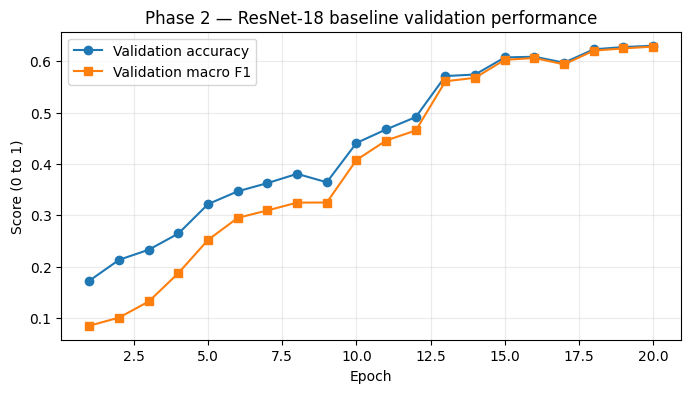

✅ PHASE 2 CHECKS PASSED


In [15]:
assert best_ckpt_path.exists() and last_ckpt_path.exists()
assert probs_npz_path.exists() and log_csv_path.exists()
assert len(training_log) == P2_EPOCHS
assert np.isfinite(probability_history.astype(np.float32)).all()
assert np.allclose(probability_history.astype(np.float32).sum(2), 1.0, atol=0.002)

with np.load(probs_npz_path) as saved:
    assert saved['probability_history'].shape == (P2_EPOCHS, len(train_dataset), NUM_CLASSES)
    assert np.array_equal(saved['selected_train_original_indices'], lt_indices)
    assert np.array_equal(saved['observed_training_labels'], observed_selected)
    assert str(saved['split_fingerprint']) == SPLIT_FINGERPRINT

training_history_df = pd.DataFrame(training_log)
display(training_history_df.tail(5))
best_row = training_history_df.loc[training_history_df['val_macro_f1'].idxmax()]
print('Best validation epoch:', int(best_row['epoch']))
print('Best validation macro-F1:', round(float(best_row['val_macro_f1']), 4))
print('Best validation accuracy:', f"{float(best_row['val_accuracy']):.2%}")
print('Best validation tail accuracy:', f"{float(best_row['val_tail_acc']):.2%}")
print('Stored probability history:', probability_history.shape)
print('Official CIFAR-10 test set: NOT evaluated in Phase 2')

plt.figure(figsize=(8, 4))
plt.plot(training_history_df['epoch'], training_history_df['val_accuracy'],
         marker='o', label='Validation accuracy')
plt.plot(training_history_df['epoch'], training_history_df['val_macro_f1'],
         marker='s', label='Validation macro F1')
plt.xlabel('Epoch')
plt.ylabel('Score (0 to 1)')
plt.title('Phase 2 — ResNet-18 baseline validation performance')
plt.legend()
plt.grid(alpha=0.25)
plt.show()
print('✅ PHASE 2 CHECKS PASSED')


`PHASE 2 CHECKS PASSED`, **(2)** last five training-log rows and best validation metrics, **(3)** any Colab error. Then we will evaluate **Confidence (C)** and **Temporal (T)** from **this same saved prediction history**, without training two unrelated baselines.


